In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, roc_curve
)

df = pd.read_csv(r"C:\Users\soulx\Downloads\customer_churn_model_v2.csv")

print(df.shape)
print(df.head())
print(df.info())

(800, 13)
    CustomerID  Age Region  TenureMonths SubscriptionType  MonthlyChargesINR  \
0  CUST-100001   57  South            33         Standard             767.25   
1  CUST-100002   44  South            45            Basic             476.72   
2  CUST-100003   64  South            57            Basic             414.81   
3  CUST-100004   57   East            44              Pro            1171.76   
4  CUST-100005   58  North            49              Pro            1130.19   

   TotalChargesINR    ContractType  SupportTickets  LatePayments  \
0         23893.97  Month-to-Month               4             1   
1         21627.46        Two Year               0             1   
2         22500.07        One Year               1             1   
3         50309.16  Month-to-Month               4             0   
4         55980.21  Month-to-Month               3             0   

  PaymentMethod AutoPay Churn  
0           UPI     Yes   Yes  
1           UPI     Yes   Yes  
2   

In [4]:
print("Missing values:")
print(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()

print(df["Churn"].value_counts())

Missing values:
CustomerID           0
Age                  0
Region               0
TenureMonths         0
SubscriptionType     0
MonthlyChargesINR    0
TotalChargesINR      0
ContractType         0
SupportTickets       0
LatePayments         0
PaymentMethod        0
AutoPay              0
Churn                0
dtype: int64
Duplicate rows: 0
Churn
No     466
Yes    334
Name: count, dtype: int64


In [5]:
X = df.drop(["CustomerID", "Churn"], axis=1)
y = df["Churn"].map({"No": 0, "Yes": 1})

X = pd.get_dummies(X, drop_first=True)

print(X.head())
print(y.value_counts())

   Age  TenureMonths  MonthlyChargesINR  TotalChargesINR  SupportTickets  \
0   57            33             767.25         23893.97               4   
1   44            45             476.72         21627.46               0   
2   64            57             414.81         22500.07               1   
3   57            44            1171.76         50309.16               4   
4   58            49            1130.19         55980.21               3   

   LatePayments  Region_East  Region_North  Region_South  Region_West  \
0             1        False         False          True        False   
1             1        False         False          True        False   
2             1        False         False          True        False   
3             0         True         False         False        False   
4             0        False          True         False        False   

   SubscriptionType_Pro  SubscriptionType_Standard  ContractType_One Year  \
0                 False    

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 640
Testing records: 160


In [7]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

In [8]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.6375
Precision: 0.576271186440678
Recall: 0.5074626865671642
F1 Score: 0.5396825396825397
ROC-AUC: 0.6785427700208634

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.73      0.70        93
           1       0.58      0.51      0.54        67

    accuracy                           0.64       160
   macro avg       0.62      0.62      0.62       160
weighted avg       0.63      0.64      0.63       160



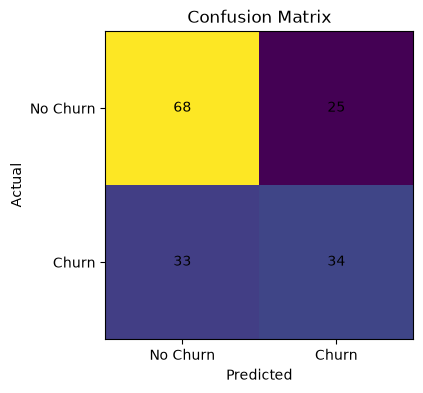

In [9]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0, 1], ["No Churn", "Churn"])
plt.yticks([0, 1], ["No Churn", "Churn"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.show()

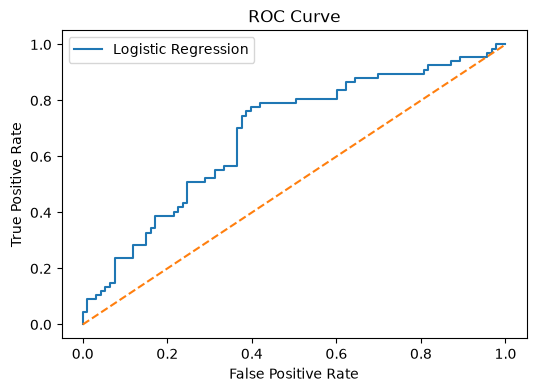

In [10]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label="Logistic Regression")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [11]:
predictions = df.loc[X_test.index, ["CustomerID"]].copy()

predictions["ActualChurn"] = y_test
predictions["PredictedChurn"] = y_pred
predictions["ChurnProbability"] = y_prob

predictions["RiskLevel"] = np.where(
    predictions["ChurnProbability"] >= 0.70,
    "High",
    np.where(
        predictions["ChurnProbability"] >= 0.40,
        "Medium",
        "Low"
    )
)

predictions = predictions.sort_values(
    "ChurnProbability",
    ascending=False
)

predictions.to_csv("customer_churn_predictions.csv", index=False)

print(predictions.head(10))

      CustomerID  ActualChurn  PredictedChurn  ChurnProbability RiskLevel
523  CUST-100524            1               1          0.826958      High
423  CUST-100424            1               1          0.816746      High
216  CUST-100217            1               1          0.736626      High
438  CUST-100439            0               1          0.731433      High
418  CUST-100419            1               1          0.725451      High
534  CUST-100535            1               1          0.724624      High
608  CUST-100609            1               1          0.722414      High
118  CUST-100119            0               1          0.698387    Medium
171  CUST-100172            0               1          0.697543    Medium
224  CUST-100225            1               1          0.683950    Medium


In [12]:
import joblib

joblib.dump(model, "churn_model.pkl")
joblib.dump(scaler, "churn_scaler.pkl")

print("Model and scaler saved successfully")

Model and scaler saved successfully


In [14]:
import pandas as pd

df = pd.read_csv(r"C:\Users\soulx\Downloads\customer_churn_model_v2.csv")

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
print(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nChurn Distribution:")
print(df["Churn"].value_counts())

Dataset Shape: (800, 13)

Column Names:
['CustomerID', 'Age', 'Region', 'TenureMonths', 'SubscriptionType', 'MonthlyChargesINR', 'TotalChargesINR', 'ContractType', 'SupportTickets', 'LatePayments', 'PaymentMethod', 'AutoPay', 'Churn']

First 5 Rows:
    CustomerID  Age Region  TenureMonths SubscriptionType  MonthlyChargesINR  \
0  CUST-100001   57  South            33         Standard             767.25   
1  CUST-100002   44  South            45            Basic             476.72   
2  CUST-100003   64  South            57            Basic             414.81   
3  CUST-100004   57   East            44              Pro            1171.76   
4  CUST-100005   58  North            49              Pro            1130.19   

   TotalChargesINR    ContractType  SupportTickets  LatePayments  \
0         23893.97  Month-to-Month               4             1   
1         21627.46        Two Year               0             1   
2         22500.07        One Year               1             1 

In [15]:
df = df.drop_duplicates()

X = df.drop(["CustomerID", "Churn"], axis=1)

y = df["Churn"].map({"No": 0, "Yes": 1})

X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Features:")
print(X.columns.tolist())

print("\nFeature shape:", X.shape)
print("\nTarget distribution:")
print(y.value_counts())

Features:
['Age', 'TenureMonths', 'MonthlyChargesINR', 'TotalChargesINR', 'SupportTickets', 'LatePayments', 'Region_East', 'Region_North', 'Region_South', 'Region_West', 'SubscriptionType_Pro', 'SubscriptionType_Standard', 'ContractType_One Year', 'ContractType_Two Year', 'PaymentMethod_Net Banking', 'PaymentMethod_UPI', 'PaymentMethod_Wallet', 'AutoPay_Yes']

Feature shape: (800, 18)

Target distribution:
Churn
0    466
1    334
Name: count, dtype: int64


In [16]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", X_train_scaled.shape[0])
print("Testing samples:", X_test_scaled.shape[0])
print("Training features:", X_train_scaled.shape[1])
print("Testing features:", X_test_scaled.shape[1])

Training samples: 640
Testing samples: 160
Training features: 18
Testing features: 18


In [17]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

y_prob = model.predict_proba(X_test_scaled)[:, 1]

print("Model training completed!")

Model training completed!


In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.6375
Precision: 0.576271186440678
Recall: 0.5074626865671642
F1 Score: 0.5396825396825397
ROC-AUC: 0.6785427700208634

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.73      0.70        93
           1       0.58      0.51      0.54        67

    accuracy                           0.64       160
   macro avg       0.62      0.62      0.62       160
weighted avg       0.63      0.64      0.63       160



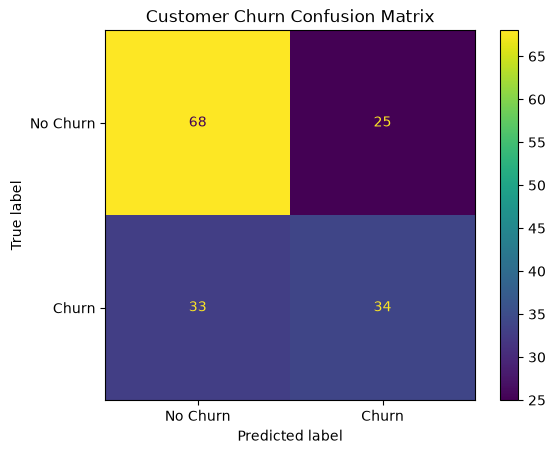

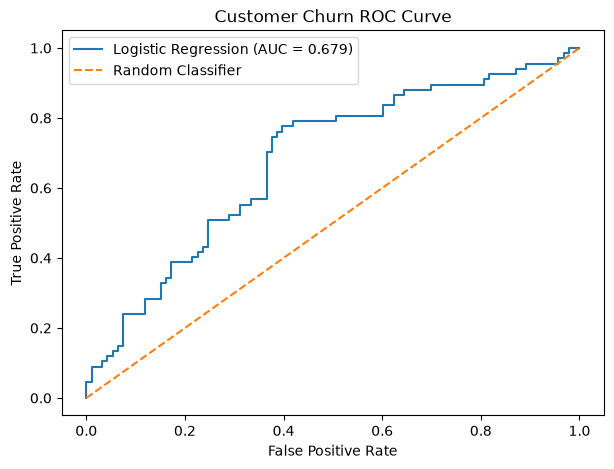

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot()
plt.title("Customer Churn Confusion Matrix")
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc_score(y_test, y_prob):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Customer Churn ROC Curve")
plt.legend()
plt.savefig("roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

In [20]:
# Scale the complete feature dataset
X_all_scaled = scaler.transform(X)

# Predict churn probability
churn_probabilities = model.predict_proba(X_all_scaled)[:, 1]

# Create prediction dataframe
predictions = pd.DataFrame({
    "CustomerID": df["CustomerID"],
    "ActualChurn": df["Churn"],
    "ChurnRiskScore": churn_probabilities,
    "PredictedChurn": model.predict(X_all_scaled)
})

# Add risk categories
predictions["RiskCategory"] = pd.cut(
    predictions["ChurnRiskScore"],
    bins=[-0.01, 0.30, 0.60, 1.00],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

predictions.to_csv("customer_churn_predictions.csv", index=False)

print("Predictions exported successfully!")
print(predictions.head())

Predictions exported successfully!
    CustomerID ActualChurn  ChurnRiskScore  PredictedChurn RiskCategory
0  CUST-100001         Yes        0.705570               1    High Risk
1  CUST-100002         Yes        0.251179               0     Low Risk
2  CUST-100003         Yes        0.258343               0     Low Risk
3  CUST-100004         Yes        0.441388               0  Medium Risk
4  CUST-100005          No        0.400455               0  Medium Risk


In [21]:
import joblib

joblib.dump(model, "churn_model.pkl")
joblib.dump(scaler, "churn_scaler.pkl")

print("Model and scaler saved!")

Model and scaler saved!
